# Étape 3 — Construction du CNN

**Termes techniques :** CNN, Conv2D, ReLU, MaxPooling2D, Flatten, Dense, Dropout, Softmax, Adam, Loss, Accuracy, EarlyStopping, ModelCheckpoint


## Cellule 1 — Imports et rechargement des données


In [1]:
import sys
import pandas as pd
import tensorflow as tf
from pathlib import Path

PROJECT_DIR = Path.cwd()
while PROJECT_DIR != PROJECT_DIR.parent and not (PROJECT_DIR / "data" / "split" / "train.csv").is_file():
    PROJECT_DIR = PROJECT_DIR.parent
SPLIT_DIR = PROJECT_DIR / "data" / "split"
sys.path.insert(0, str(PROJECT_DIR))
from src.data_pipeline import load_manifest, make_augmentation

IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42
train_table = pd.read_csv(SPLIT_DIR / "train.csv")
class_names = sorted(train_table["label"].unique())
class_to_id = {name: index for index, name in enumerate(class_names)}
N_CLASSES = len(class_names)
train_ds = load_manifest(SPLIT_DIR / "train.csv", class_to_id, IMG_SIZE, BATCH_SIZE, shuffle=True, seed=SEED)
val_ds = load_manifest(SPLIT_DIR / "validation.csv", class_to_id, IMG_SIZE, BATCH_SIZE)

augmentation = make_augmentation(SEED)
train_ds = train_ds.map(lambda images, labels: (augmentation(images, training=True), labels))
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
print("Classes :", class_to_id)
print("Images train :", len(train_table), "| validation :", len(pd.read_csv(SPLIT_DIR / "validation.csv")))

TensorFlow : 2.21.0
Classes et ordre : {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}
Images train : 11923 | validation : 2555
Forme d'un lot : (32, 150, 150, 3) | plage des pixels : 0.0 à 1.0


## Cellule 2 — Construction du CNN


In [2]:
model = tf.keras.Sequential([

    # --- Bloc 1 : détection des contours et textures simples ---
    tf.keras.layers.Input(shape=(150, 150, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    # --- Bloc 2 : détection de formes plus complexes ---
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    # --- Bloc 3 : détection de structures de haut niveau ---
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    # --- Mise à plat : on transforme les cartes 2D en vecteur ---
    tf.keras.layers.Flatten(),

    # --- Classification ---
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.4),          # évite l'overfitting
    tf.keras.layers.Dense(N_CLASSES, activation="softmax")  # 6 classes
])

print("Modèle construit.")

Modèle construit.


## Cellule 3 — Compilation du modèle


In [3]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modèle compilé.")

Modèle compilé.


## Cellule 4 — Résumé de l'architecture


In [4]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

## Cellule 5 — Callbacks


In [5]:
MODEL_PATH = PROJECT_DIR / "models" / "cnn_scenevision.keras"
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

best_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6
)
print("Callbacks prêts. Meilleur modèle :", MODEL_PATH)


Callbacks prêts. Meilleur modèle : c:\Users\Olaya\Desktop\sprint_2\SceneVision AI\models\cnn_scenevision.keras


## Cellule 6 — Entraînement


In [6]:
history = model.fit(
    train_ds,
    epochs=20,
    validation_data=val_ds,
    callbacks=[best_checkpoint, early_stop, reduce_lr],
    shuffle=False
)

Epoch 1/20


c:\Program Files\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


373/373 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.5372 - loss: 1.1689
Epoch 1: val_loss improved from None to 1.01583, saving model to c:\Users\Olaya\Desktop\sprint_2\SceneVision AI\models\cnn_scenevision.keras

Epoch 1: finished saving model to c:\Users\Olaya\Desktop\sprint_2\SceneVision AI\models\cnn_scenevision.keras
373/373 ━━━━━━━━━━━━━━━━━━━━ 90s 240ms/step - accuracy: 0.5372 - loss: 1.1689 - val_accuracy: 0.6149 - val_loss: 1.0158 - learning_rate: 0.0010
Epoch 2/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step - accuracy: 0.6497 - loss: 0.9296
Epoch 2: val_loss improved from 1.01583 to 0.75344, saving model to c:\Users\Olaya\Desktop\sprint_2\SceneVision AI\models\cnn_scenevision.keras

Epoch 2: finished saving model to c:\Users\Olaya\Desktop\sprint_2\SceneVision AI\models\cnn_scenevision.keras
373/373 ━━━━━━━━━━━━━━━━━━━━ 106s 284ms/step - accuracy: 0.6497 - loss: 0.9296 - val_accuracy: 0.7237 - val_loss: 0.7534 - learning_rate: 0.0010
Epoch 3/20
373/373 ━━━━━━━━━━━━━━━━━━━━

## Cellule 7 — Courbes Loss et Accuracy


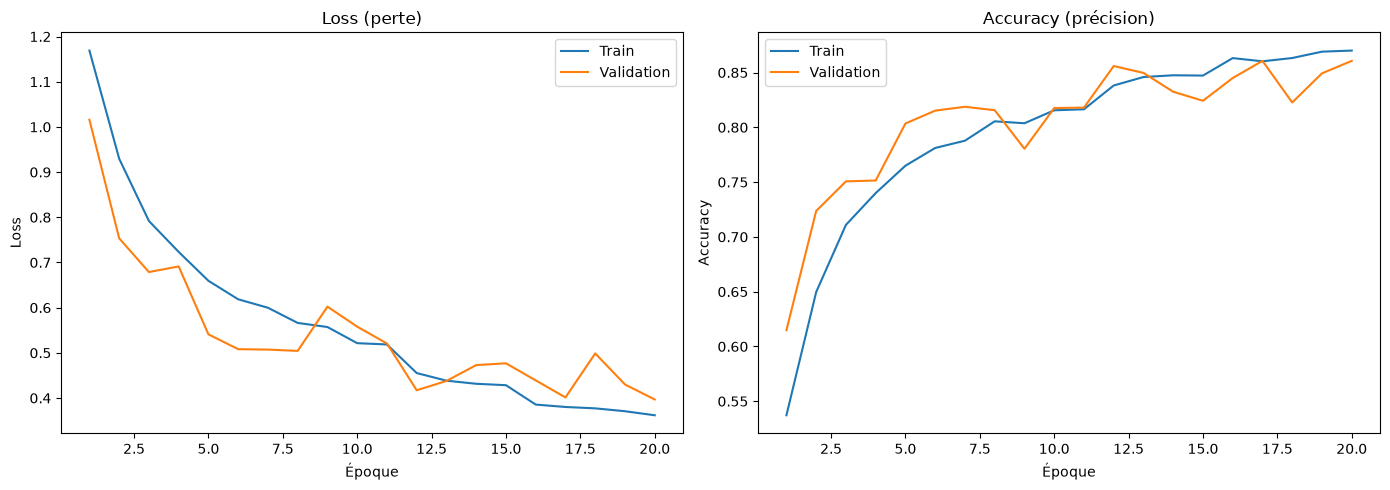

In [7]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Courbe Loss ---
axes[0].plot(epochs_range, history.history['loss'],     label='Train')
axes[0].plot(epochs_range, history.history['val_loss'], label='Validation')
axes[0].set_title('Loss (perte)')
axes[0].set_xlabel('Époque')
axes[0].set_ylabel('Loss')
axes[0].legend()

# --- Courbe Accuracy ---
axes[1].plot(epochs_range, history.history['accuracy'],     label='Train')
axes[1].plot(epochs_range, history.history['val_accuracy'], label='Validation')
axes[1].set_title('Accuracy (précision)')
axes[1].set_xlabel('Époque')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

## Cellule 8 — Interprétation des courbes


In [8]:
final_train_acc = history.history['accuracy'][-1]
final_val_acc   = history.history['val_accuracy'][-1]
best_val_acc    = max(history.history['val_accuracy'])
n_epochs        = len(history.history['loss'])

print(f'Époques réalisées     : {n_epochs}')
print(f'Accuracy train finale : {final_train_acc:.2%}')
print(f'Accuracy val finale   : {final_val_acc:.2%}')
print(f'Meilleure val accuracy: {best_val_acc:.2%}')

Époques réalisées     : 20
Accuracy train finale : 87.01%
Accuracy val finale   : 86.07%
Meilleure val accuracy: 86.07%


## Cellule 9 — Sauvegarde du modèle


In [9]:
# ModelCheckpoint a conservé le meilleur modèle selon la val_loss.
print("Meilleur modèle enregistré :", MODEL_PATH.exists())
print("Chemin :", MODEL_PATH)


Meilleur modèle enregistré : True
Chemin : c:\Users\Olaya\Desktop\sprint_2\SceneVision AI\models\cnn_scenevision.keras


## Évaluation du modèle